# Segmentation Results

### Table 5 — Main Ablation Study: Validation Results

The results of the main ablation study are summarized in **Table 5**. This cell calculates the mean and 95% confidence interval (CI) across five independent runs (Seeds 41–45) for each model. The final table reports the validation results as Mean ± 95% CI.

In [ ]:

# ================================================================
# Main Ablation Study — Statistical Analysis and Final Paper Table
# Five Seeds: 41, 42, 43, 44, 45
# Reported values: Mean ± 95% CI Margin
# ================================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import t
from IPython.display import display

# ================================================================
# 1. Configuration
# ================================================================

PROJECT_DIR = r".."

RAW_RESULTS_DIR = os.path.join(
    PROJECT_DIR,
    "Main_Ablation_Study",
    "Results"
)

SEEDS = [41, 42, 43, 44, 45]

MODEL_ORDER = [
    "2D_Baseline",
    "2.5D_Baseline",
    "2.5D_EncAtt",
    "2.5D_DecAtt",
    "2.5D_FullAtt"
]

METRICS = {
    "dice": "Dice",
    "iou": "IoU",
    "recall": "Sensitivity",
    "precision": "Precision",
    "auc": "AUC"
}

REQUIRED_COLUMNS = [
    "name",
    "seed",
    "split",
    "dice",
    "iou",
    "precision",
    "recall",
    "accuracy",
    "specificity",
    "auc"
]

# ================================================================
# 2. Load Results from All Five Seeds
# ================================================================

all_results = []

for seed in SEEDS:

    file_name = f"Final_Ablation_Results_patch320_PNG_S{seed}.csv"

    file_path = os.path.join(
        RAW_RESULTS_DIR,
        file_name
    )

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"Results file not found:\n{file_path}"
        )

    df = pd.read_csv(file_path)

    missing_columns = [
        col for col in REQUIRED_COLUMNS
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing columns in {file_name}: {missing_columns}"
        )

    if not (df["seed"] == seed).all():
        raise ValueError(
            f"Seed mismatch detected in {file_name}"
        )

    all_results.append(df)

results_df = pd.concat(
    all_results,
    ignore_index=True
)

# ================================================================
# 3. Validate Dataset
# ================================================================

expected_rows = len(MODEL_ORDER) * len(SEEDS) * 2

if len(results_df) != expected_rows:
    raise ValueError(
        f"Expected {expected_rows} rows, "
        f"but found {len(results_df)}."
    )

if results_df.duplicated(
    subset=["name", "seed", "split"]
).any():
    raise ValueError(
        "Duplicate model/seed/split combinations detected."
    )

if set(results_df["name"].unique()) != set(MODEL_ORDER):
    raise ValueError("Unexpected model names detected.")

if set(results_df["split"].unique()) != {"Train", "Val"}:
    raise ValueError("Unexpected split names detected.")

print("All five seed files loaded and validated successfully.")
print(f"Total records: {len(results_df)}")

# ================================================================
# 4. Calculate Mean, SD, SE and 95% Confidence Interval
# ================================================================

N = len(SEEDS)
DEGREES_OF_FREEDOM = N - 1

t_critical = t.ppf(
    0.975,
    df=DEGREES_OF_FREEDOM
)

statistics = []

for model in MODEL_ORDER:

    for split in ["Train", "Val"]:

        model_data = results_df[
            (results_df["name"] == model) &
            (results_df["split"] == split)
        ]

        model_data = model_data.sort_values("seed")

        if len(model_data) != N:
            raise ValueError(
                f"Expected {N} runs for {model} - {split}, "
                f"found {len(model_data)}."
            )

        for metric, metric_label in METRICS.items():

            values = model_data[metric].to_numpy(dtype=float)

            if not np.isfinite(values).all():
                raise ValueError(
                    f"Non-finite values found: {model}, {split}, {metric}"
                )

            mean_value = np.mean(values)

            # Sample standard deviation
            sd_value = np.std(values, ddof=1)

            # Standard error
            se_value = sd_value / np.sqrt(N)

            # 95% CI margin
            ci_margin = t_critical * se_value

            ci_lower = mean_value - ci_margin
            ci_upper = mean_value + ci_margin

            statistics.append({
                "Model": model,
                "Split": split,
                "Metric": metric_label,
                "N": N,
                "Mean": mean_value * 100,
                "SD": sd_value * 100,
                "SE": se_value * 100,
                "CI_Lower": ci_lower * 100,
                "CI_Upper": ci_upper * 100,
                "CI_Margin": ci_margin * 100
            })

stats_df = pd.DataFrame(statistics)

# ================================================================
# 5. Display Detailed Statistical Results
# ================================================================

print("\n" + "=" * 100)
print("DETAILED STATISTICAL RESULTS")
print("Mean, SD and 95% Confidence Interval")
print("=" * 100)

display(
    stats_df.round(3)
)

# ================================================================
# 6. Generate Final Main Ablation Study Table
#    Validation Results: Mean ± 95% CI Margin
# ================================================================

paper_rows = []

# Ablation factor rows
ablation_rows = [
    {
        "Experiments": "Ablation factor",
        "Evaluation": "2.5D input",
        "2D_Baseline": "-",
        "2.5D_Baseline": "✓",
        "2.5D_EncAtt": "✓",
        "2.5D_DecAtt": "✓",
        "2.5D_FullAtt": "✓"
    },
    {
        "Experiments": "",
        "Evaluation": "Encoder attention",
        "2D_Baseline": "-",
        "2.5D_Baseline": "-",
        "2.5D_EncAtt": "✓",
        "2.5D_DecAtt": "-",
        "2.5D_FullAtt": "✓"
    },
    {
        "Experiments": "",
        "Evaluation": "Decoder attention",
        "2D_Baseline": "-",
        "2.5D_Baseline": "-",
        "2.5D_EncAtt": "-",
        "2.5D_DecAtt": "✓",
        "2.5D_FullAtt": "✓"
    }
]

paper_rows.extend(ablation_rows)

# Evaluation metric section
metric_section = {
    "Experiments": "Evaluation metrics",
    "Evaluation": "",
    **{model: "" for model in MODEL_ORDER}
}

paper_rows.append(metric_section)

# Validation statistics only
val_stats = stats_df[
    stats_df["Split"] == "Val"
].copy()

# Add metric rows in the requested order
for metric, metric_label in METRICS.items():

    metric_row = {
        "Experiments": "",
        "Evaluation": metric_label
    }

    for model in MODEL_ORDER:

        row = val_stats[
            (val_stats["Model"] == model) &
            (val_stats["Metric"] == metric_label)
        ]

        if len(row) != 1:
            raise ValueError(
                f"Missing or duplicate statistics: {model}, {metric_label}"
            )

        mean_value = row.iloc[0]["Mean"]
        ci_margin = row.iloc[0]["CI_Margin"]

        metric_row[model] = (
            f"{mean_value:.2f} ± {ci_margin:.2f}%"
        )

    paper_rows.append(metric_row)

# Final table
paper_table = pd.DataFrame(
    paper_rows,
    columns=[
        "Experiments",
        "Evaluation",
        *MODEL_ORDER
    ]
)

# ================================================================
# 7. Display Final Paper Table
# ================================================================

print("\n" + "=" * 120)
print("FINAL MAIN ABLATION STUDY TABLE")
print("Validation Results — Mean ± 95% CI")
print("=" * 120)

display(paper_table)

print("\nStatistical analysis completed successfully.")


All five seed files loaded and validated successfully.
Total records: 50

DETAILED STATISTICAL RESULTS
Mean, SD and 95% Confidence Interval


,Model,Split,Metric,N,Mean,SD,SE,CI_Lower,CI_Upper,CI_Margin
0,2D_Baseline,Train,Dice,5,79.452,2.886,1.291,75.868,83.036,3.584
1,2D_Baseline,Train,IoU,5,65.983,3.864,1.728,61.185,70.781,4.798
2,2D_Baseline,Train,Sensitivity,5,84.994,3.935,1.760,80.108,89.881,4.886
3,2D_Baseline,Train,Precision,5,74.601,2.076,0.928,72.023,77.179,2.578
4,2D_Baseline,Train,AUC,5,98.976,0.560,0.251,98.280,99.672,0.696
5,2D_Baseline,Val,Dice,5,69.126,1.833,0.820,66.850,71.402,2.276
6,2D_Baseline,Val,IoU,5,52.842,2.117,0.947,50.213,55.471,2.629
7,2D_Baseline,Val,Sensitivity,5,64.669,2.256,1.009,61.868,67.470,2.801
8,2D_Baseline,Val,Precision,5,74.275,1.897,0.848,71.920,76.630,2.355
9,2D_Baseline,Val,AUC,5,94.749,1.782,0.797,92.536,96.962,2.213



FINAL MAIN ABLATION STUDY TABLE
Validation Results — Mean ± 95% CI


,Experiments,Evaluation,2D_Baseline,2.5D_Baseline,2.5D_EncAtt,2.5D_DecAtt,2.5D_FullAtt
0,Ablation factor,2.5D input,-,✓,✓,✓,✓
1,,Encoder attention,-,-,✓,-,✓
2,,Decoder attention,-,-,-,✓,✓
3,Evaluation metrics,,,,,,
4,,Dice,69.13 ± 2.28%,71.67 ± 1.27%,72.48 ± 1.44%,74.88 ± 2.18%,75.36 ± 3.51%
5,,IoU,52.84 ± 2.63%,55.85 ± 1.56%,56.84 ± 1.75%,59.87 ± 2.79%,60.52 ± 4.48%
6,,Sensitivity,64.67 ± 2.80%,67.15 ± 3.36%,68.29 ± 2.13%,69.99 ± 3.69%,71.70 ± 4.94%
7,,Precision,74.27 ± 2.36%,77.10 ± 4.93%,77.24 ± 1.78%,80.57 ± 1.00%,79.50 ± 3.33%
8,,AUC,94.75 ± 2.21%,93.94 ± 1.11%,95.18 ± 0.99%,92.52 ± 1.62%,94.10 ± 1.37%



Statistical analysis completed successfully.


-----------------

### Table 10 — Final Test Results: 2D Baseline vs. 2.5D DecAtt

This cell summarizes the final test results of the 2D_Baseline and 2.5D_DecAtt models across five independent runs (Seeds 41–45).

The cell reads the five per-seed test result CSV files and extracts the results for the Test split. It then calculates the mean and 95% confidence interval (CI) for each evaluation metric across the five runs.

The results are displayed in two tables:
- **Per-seed Test Results:** Individual test metrics for each model and seed.
- **Final Test Results:** Mean ± 95% CI for Dice score, IoU, Sensitivity, and Precision.

The results are presented in Table 10 of the manuscript.

**Note:** The original `recall` column in the CSV files is displayed as `sensitivity` in the output tables.

In [ ]:

# ============================================================
# Final Test Results Summary 
# 2D Baseline vs 2.5D DecAtt
# Five independent runs (Seeds 41–45)
#
# Only Test split is used.
# Results are reported as Mean ± 95% CI.
#
# No training or inference is performed.
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import t


# ============================================================
# 1. Configuration
# ============================================================

RESULTS_DIR = r"Results"

SEEDS = [41, 42, 43, 44, 45]

FILES = {
    seed: (
        f"Final_Test_Results_Baseline_DecAtt_patch320_PNG_S{seed}.csv"
    )
    for seed in SEEDS
}

MODEL_MAP = {
    "Baseline_2D": "2D_Baseline",
    "2D_Baseline": "2D_Baseline",
    "Baseline_2.5D_DecAtt": "2.5D_DecAtt",
    "2.5D_DecAtt": "2.5D_DecAtt",
}

MODEL_ORDER = [
    "2D_Baseline",
    "2.5D_DecAtt"
]

METRICS = [
    "dice",
    "iou",
    "recall",
    "precision"
]

METRIC_LABELS = {
    "dice": "Dice score",
    "iou": "IoU",
    "recall": "Sensitivity",
    "precision": "Precision"
}

SPLIT_TO_USE = "test"


# ============================================================
# 2. Read and combine five seed files
# ============================================================

all_results = []

for seed, filename in FILES.items():

    file_path = os.path.join(
        RESULTS_DIR,
        filename
    )

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"File not found:\n{file_path}"
        )

    df = pd.read_csv(file_path)

    # Normalize model names
    df["model"] = df["name"].replace(MODEL_MAP)

    # Keep ONLY Test split
    df["split"] = (
        df["split"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    df = df[
        df["split"] == SPLIT_TO_USE
    ].copy()

    # Keep only the two selected models
    df = df[
        df["model"].isin(MODEL_ORDER)
    ].copy()

    if df.empty:
        raise ValueError(
            f"No Test results found in {filename}"
        )

    df["seed"] = seed

    all_results.append(df)


combined_df = pd.concat(
    all_results,
    ignore_index=True
)


# ============================================================
# 3. Check required columns
# ============================================================

missing_metrics = [
    metric for metric in METRICS
    if metric not in combined_df.columns
]

if missing_metrics:
    raise ValueError(
        f"Missing metric columns: {missing_metrics}\n"
        f"Available columns: {combined_df.columns.tolist()}"
    )


# ============================================================
# 4. Validate one Test result per model per seed
# ============================================================

for model_name in MODEL_ORDER:

    model_data = combined_df[
        combined_df["model"] == model_name
    ]

    available_seeds = sorted(
        model_data["seed"].unique().tolist()
    )

    if available_seeds != SEEDS:
        raise ValueError(
            f"Incomplete seed results for {model_name}. "
            f"Found: {available_seeds}"
        )

    if len(model_data) != len(SEEDS):
        raise ValueError(
            f"Expected exactly one Test row per seed for "
            f"{model_name}, but found {len(model_data)} rows."
        )


# ============================================================
# 5. Calculate Mean ± 95% CI across five seeds
# ============================================================

def calculate_mean_ci(values):

    values = np.asarray(values, dtype=float)

    n = len(values)

    if n != 5:
        raise ValueError(
            f"Expected 5 values, received {n}."
        )

    mean = np.mean(values)

    sd = np.std(
        values,
        ddof=1
    )

    ci = (
        t.ppf(0.975, df=n - 1)
        * sd / np.sqrt(n)
    )

    return mean, ci


summary_rows = []

for metric in METRICS:

    row = {
        "Evaluation metrics": METRIC_LABELS[metric]
    }

    for model_name in MODEL_ORDER:

        values = combined_df.loc[
            combined_df["model"] == model_name
        ].sort_values("seed")[metric].astype(float).to_numpy()

        mean, ci = calculate_mean_ci(values)

        row[model_name] = (
            f"{mean * 100:.2f} ± {ci * 100:.2f}%"
        )

    summary_rows.append(row)


final_test_table = pd.DataFrame(
    summary_rows
)


# ============================================================
# 6. Display per-seed Test results
# ============================================================

verification_table = combined_df[
    ["model", "seed"] + METRICS
].sort_values(
    ["model", "seed"]
).reset_index(drop=True)

print("\n" + "=" * 75)
print("PER-SEED TEST RESULTS")
print("=" * 75)

verification_table = verification_table.rename(
    columns={"recall": "sensitivity"}
)

display(verification_table)


# ============================================================
# 7. Display final summary — Mean ± 95% CI
# ============================================================

print("\n" + "=" * 75)
print("FINAL TEST RESULTS — MEAN ± 95% CI (5 SEEDS)")
print("=" * 75)

display(final_test_table)




PER-SEED TEST RESULTS


,model,seed,dice,iou,sensitivity,precision
0,2.5D_DecAtt,41,0.721517,0.564354,0.680456,0.767852
1,2.5D_DecAtt,42,0.690704,0.527538,0.629649,0.764871
2,2.5D_DecAtt,43,0.702334,0.541229,0.641161,0.776411
3,2.5D_DecAtt,44,0.711916,0.552693,0.653684,0.781537
4,2.5D_DecAtt,45,0.696348,0.534151,0.606701,0.817081
5,2D_Baseline,41,0.686719,0.522904,0.616977,0.774239
6,2D_Baseline,42,0.702981,0.541997,0.672868,0.735915
7,2D_Baseline,43,0.663838,0.496824,0.625064,0.707740
8,2D_Baseline,44,0.677287,0.512044,0.609051,0.762742
9,2D_Baseline,45,0.687499,0.523808,0.664190,0.712503



FINAL TEST RESULTS — MEAN ± 95% CI (5 SEEDS)


,Evaluation metrics,2D_Baseline,2.5D_DecAtt
0,Dice score,68.37 ± 1.79%,70.46 ± 1.53%
1,IoU,51.95 ± 2.06%,54.40 ± 1.83%
2,Sensitivity,63.76 ± 3.59%,64.23 ± 3.41%
3,Precision,73.86 ± 3.67%,78.16 ± 2.60%


---------------

### Table 6 — HD95 and Empty Prediction Rate

**Prerequisite:** Before running this cell, execute the required cells in the `Main_Ablation_Study.ipynb` notebook. In particular, the model architecture, data loading functions, dataset splits, and required variables (`train_ids`, `val_ids`, and `test_ids`) must be defined and available in the current notebook session. This cell depends on those definitions and the saved model checkpoints. It does not perform any model training.

This cell evaluates the five segmentation configurations across five independent runs (Seeds 41–45) using their saved checkpoints.

The standard HD95 is calculated for each slice as the maximum of the 95th-percentile surface distances in the two directions. Slices with empty ground-truth masks or empty predicted masks are excluded from the HD95 calculation. The empty prediction rate is calculated separately over slices with non-empty ground-truth masks.

Results are summarized across the five runs and reported as mean ± 95% confidence interval (CI). HD95 is expressed in pixels (px), and the empty prediction rate is expressed as a percentage.

The results are reported in Table 6 of the manuscript.

In [ ]:

# ============================================================
# Table 6 — HD95 and Empty Prediction Rate
# Main Ablation Study: 5 Configurations x 5 Seeds
#
# No training is performed. Saved checkpoints are evaluated
# on the validation set.
#
# HD95:
#   For each valid slice:
#   max(P95(prediction surface -> GT surface),
#       P95(GT surface -> prediction surface))
#
#   Slices with empty GT or empty predictions are excluded
#   from the HD95 calculation.
#
# Empty prediction rate:
#   Number of empty predictions / number of non-empty GT masks
#
# Final reporting:
#   Mean ± 95% t-based confidence interval across five seeds.
#
# Output:
#   - Table6_HD95_EmptyRate.csv
#   - Table6_PerSeed_Results.csv
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from scipy.ndimage import binary_erosion, distance_transform_edt
from scipy.stats import t as t_dist


# ============================================================
# 1. Configuration
# ============================================================

CKPT_DIR = Path("Checkpoints")

FILE_TEMPLATE = "best_model_{tag}_S{seed}.pt"

SEEDS = [41, 42, 43, 44, 45]

CONFIGS = {
    # name: (checkpoint tag, input channels, 2.5D, encoder attention, decoder attention)

    "2D_Baseline": (
        "Baseline_2D", 1, False, False, False
    ),

    "2.5D_Baseline": (
        "Baseline_2.5D", 3, True, False, False
    ),

    "2.5D_EncAtt": (
        "2.5D_EncAtt", 3, True, True, False
    ),

    "2.5D_DecAtt": (
        "2.5D_DecAtt", 3, True, False, True
    ),

    "2.5D_FullAtt": (
        "2.5D_FullAtt", 3, True, True, True
    )
}

MODEL_ORDER = [
    "2D_Baseline",
    "2.5D_Baseline",
    "2.5D_EncAtt",
    "2.5D_DecAtt",
    "2.5D_FullAtt"
]

SPLIT = "val"

THRESHOLD = 0.5
BATCH_SIZE_EVAL = 16
IMG_SIDE = 320

OUT_DIR = Path("Main_Ablation_Study_Results")
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Surface extraction and standard HD95
# ============================================================

def surface_of(mask):
    """
    Extract the binary surface using morphological erosion.
    """
    mask = np.asarray(mask, dtype=bool)

    return mask ^ binary_erosion(
        mask,
        border_value=0
    )


def calculate_hd95(pred, gt):
    """
    Standard symmetric HD95 in pixels.

    HD95 = max(
        percentile 95 of prediction-to-GT surface distances,
        percentile 95 of GT-to-prediction surface distances
    )

    Returns NaN if either mask is empty.
    """

    pred = np.asarray(pred, dtype=bool)
    gt = np.asarray(gt, dtype=bool)

    if not pred.any() or not gt.any():
        return np.nan

    pred_surface = surface_of(pred)
    gt_surface = surface_of(gt)

    # Prediction surface -> nearest GT surface
    d_pred_to_gt = distance_transform_edt(
        ~gt_surface
    )[pred_surface]

    # GT surface -> nearest prediction surface
    d_gt_to_pred = distance_transform_edt(
        ~pred_surface
    )[gt_surface]

    hd95 = max(
        np.percentile(d_pred_to_gt, 95),
        np.percentile(d_gt_to_pred, 95)
    )

    return float(hd95)


# ============================================================
# 3. Evaluate one checkpoint
# ============================================================

@torch.no_grad()
def evaluate_checkpoint(model, loader, device):

    hd95_values = []
    gt_nonempty_count = 0
    empty_prediction_count = 0

    for xb, yb in loader:

        xb = xb.to(device)

        output = model(xb)

        logits = (
            output[0]
            if isinstance(output, (tuple, list))
            else output
        )

        pred = (
            torch.sigmoid(logits) > THRESHOLD
        ).cpu().numpy()[:, 0]

        gt = (
            yb[:, 0].cpu().numpy() > 0.5
        )

        for j in range(pred.shape[0]):

            pred_mask = pred[j]
            gt_mask = gt[j]

            # Only GT-positive slices are considered
            if not gt_mask.any():
                continue

            gt_nonempty_count += 1

            # Empty prediction rate
            if not pred_mask.any():

                empty_prediction_count += 1

                # HD95 is undefined for an empty prediction
                continue

            # Standard HD95 for valid masks
            hd95 = calculate_hd95(
                pred_mask,
                gt_mask
            )

            if not np.isnan(hd95):
                hd95_values.append(hd95)

    if gt_nonempty_count == 0:
        raise ValueError(
            "No non-empty ground-truth masks were found."
        )

    hd95_mean = (
        float(np.mean(hd95_values))
        if len(hd95_values) > 0
        else np.nan
    )

    empty_rate = (
        empty_prediction_count / gt_nonempty_count
    )

    return {
        "hd95_mean": hd95_mean,
        "empty_prediction_rate": empty_rate,
        "n_gt_nonempty": gt_nonempty_count,
        "n_hd95_valid": len(hd95_values),
        "n_empty_predictions": empty_prediction_count
    }


# ============================================================
# 4. Mean, SD and 95% CI across seeds
# ============================================================

def calculate_ci(values):

    values = np.asarray(values, dtype=float)

    values = values[np.isfinite(values)]

    n = len(values)

    if n < 2:
        raise ValueError(
            "At least two valid seed results are required."
        )

    mean = np.mean(values)
    sd = np.std(values, ddof=1)

    ci_half_width = (
        t_dist.ppf(0.975, df=n - 1)
        * sd / np.sqrt(n)
    )

    return {
        "mean": float(mean),
        "sd": float(sd),
        "ci_half_width": float(ci_half_width),
        "ci_lower": float(mean - ci_half_width),
        "ci_upper": float(mean + ci_half_width)
    }


# ============================================================
# 5. Prepare validation loader
# ============================================================

if "SwinUNetAdaptive_DS" not in globals():
    raise RuntimeError(
        "SwinUNetAdaptive_DS is not defined. "
        "Run the model definition cell first."
    )

if "make_loaders_ablation" not in globals():
    raise RuntimeError(
        "make_loaders_ablation is not defined. "
        "Run the data loader definition cell first."
    )

if "train_ids" not in globals() or "val_ids" not in globals():
    raise RuntimeError(
        "train_ids and val_ids must be defined."
    )

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Cache loaders separately for 2D and 2.5D inputs
loaders = {}


def get_validation_loader(use_25d):

    if use_25d not in loaders:

        _, dl_va, _ = make_loaders_ablation(
            train_ids,
            val_ids,
            test_ids,
            use_25d=use_25d,
            use_crop=False,
            batch_size=BATCH_SIZE_EVAL,
            fraction=1.0,
            num_workers=0
        )

        loaders[use_25d] = dl_va

    return loaders[use_25d]


print("=" * 75)
print("TABLE 6 — HD95 AND EMPTY PREDICTION RATE")
print("=" * 75)

print(f"Evaluation split: {SPLIT}")
print(f"Seeds: {SEEDS}")
print(f"Device: {device}")
print(f"Threshold: {THRESHOLD}")


# ============================================================
# 6. Evaluate all configurations and seeds
# ============================================================

seed_results = []

for model_name in MODEL_ORDER:

    tag, in_ch, use_25d, enc_att, dec_att = CONFIGS[model_name]

    print("\n" + "-" * 75)
    print(f"Model: {model_name}")
    print("-" * 75)

    loader = get_validation_loader(use_25d)

    for seed in SEEDS:

        checkpoint_path = (
            CKPT_DIR /
            FILE_TEMPLATE.format(
                tag=tag,
                seed=seed
            )
        )

        if not checkpoint_path.exists():

            raise FileNotFoundError(
                f"Checkpoint not found:\n{checkpoint_path}"
            )

        model = SwinUNetAdaptive_DS(
            in_ch=in_ch,
            use_enc_att=enc_att,
            use_dec_att=dec_att
        ).to(device)

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
        
        # Support common checkpoint formats
        if isinstance(checkpoint, dict):

            for key in [
                "model_state_dict",
                "state_dict",
                "model_state"
            ]:

                if key in checkpoint:
                    checkpoint = checkpoint[key]
                    break

        model.load_state_dict(checkpoint)
        model.eval()

        metrics = evaluate_checkpoint(
            model,
            loader,
            device
        )

        row = {
            "model": model_name,
            "seed": seed,
            **metrics
        }

        seed_results.append(row)

        print(
            f"Seed {seed}: "
            f"HD95 = {metrics['hd95_mean']:.2f} px | "
            f"Empty prediction rate = "
            f"{metrics['empty_prediction_rate'] * 100:.2f}% | "
            f"Valid HD95 slices = {metrics['n_hd95_valid']}"
        )

        del model
        del checkpoint

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# 7. Save per-seed results
# ============================================================

seed_df = pd.DataFrame(seed_results)

seed_output = (
    OUT_DIR / "Table6_PerSeed_Results.csv"
)

seed_df.to_csv(
    seed_output,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 8. Calculate final Mean ± 95% CI
# ============================================================

summary_rows = []

for model_name in MODEL_ORDER:

    model_data = seed_df[
        seed_df["model"] == model_name
    ]

    if len(model_data) != len(SEEDS):
        raise ValueError(
            f"{model_name}: expected {len(SEEDS)} seeds, "
            f"but found {len(model_data)}."
        )

    hd95_stats = calculate_ci(
        model_data["hd95_mean"]
    )

    empty_stats = calculate_ci(
        model_data["empty_prediction_rate"]
    )

    summary_rows.append({

        "Model": model_name,

        "HD95 (px)": (
            f"{hd95_stats['mean']:.2f} ± "
            f"{hd95_stats['ci_half_width']:.2f}"
        ),

        "Empty prediction rate": (
            f"{empty_stats['mean'] * 100:.2f} ± "
            f"{empty_stats['ci_half_width'] * 100:.2f}%"
        )
    })


table6 = pd.DataFrame(summary_rows)


# ============================================================
# 9. Display and save Table 6
# ============================================================

print("\n" + "=" * 75)
print("TABLE 6 — FINAL RESULTS (MEAN ± 95% CI)")
print("=" * 75)

display(table6)

table6_output = (
    OUT_DIR / "Table6_HD95_EmptyRate.csv"
)

table6.to_csv(
    table6_output,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved files:")
print(f"1. {seed_output}")
print(f"2. {table6_output}")

print("\nEvaluation completed successfully.")


TABLE 6 — HD95 AND EMPTY PREDICTION RATE
Evaluation split: val
Seeds: [41, 42, 43, 44, 45]
Device: cuda
Threshold: 0.5

---------------------------------------------------------------------------
Model: 2D_Baseline
---------------------------------------------------------------------------
Training samples: 9,845
Validation samples: 2,082
Test samples: 2,016
Seed 41: HD95 = 35.46 px | Empty prediction rate = 12.44% | Valid HD95 slices = 1823
Seed 42: HD95 = 32.70 px | Empty prediction rate = 12.34% | Valid HD95 slices = 1825
Seed 43: HD95 = 49.26 px | Empty prediction rate = 9.46% | Valid HD95 slices = 1885
Seed 44: HD95 = 31.72 px | Empty prediction rate = 15.03% | Valid HD95 slices = 1769
Seed 45: HD95 = 33.78 px | Empty prediction rate = 10.76% | Valid HD95 slices = 1858

---------------------------------------------------------------------------
Model: 2.5D_Baseline
---------------------------------------------------------------------------
Training samples: 9,845
Validation sample

,Model,HD95 (px),Empty prediction rate
0,2D_Baseline,36.59 ± 8.97,12.01 ± 2.60%
1,2.5D_Baseline,29.20 ± 14.98,11.08 ± 2.64%
2,2.5D_EncAtt,28.78 ± 4.59,11.97 ± 2.55%
3,2.5D_DecAtt,19.34 ± 4.68,10.58 ± 1.10%
4,2.5D_FullAtt,21.08 ± 11.08,8.90 ± 3.43%



Saved files:
1. Main_Ablation_Study_Results\Table6_PerSeed_Results.csv
2. Main_Ablation_Study_Results\Table6_HD95_EmptyRate.csv

Evaluation completed successfully.


--------------------------------

### Table 10 - Test Set Evaluation: HD95 and Empty Prediction Rate

**Prerequisite:** Before running this cell, execute the required cells in `Main_Ablation_Study.ipynb`. The model architecture, data loading functions, dataset splits, and required variables (`train_ids`, `val_ids`, and `test_ids`) must be defined and available in the current notebook session.

This cell evaluates the saved checkpoints of the 2D Baseline and 2.5D Decoder Attention (DecAtt) models on the held-out test set across five independent runs (Seeds 41–45). No additional model training is performed.

The standard HD95 is calculated for each valid slice as the maximum of the 95th-percentile surface distances in the two directions. Slices with empty ground-truth masks or empty predicted masks are excluded from the HD95 calculation. The empty prediction rate is calculated separately over slices with non-empty ground-truth masks.

Results are reported as mean ± 95% confidence interval (CI) across the five runs. HD95 is expressed in pixels (px), and the empty prediction rate is expressed as a percentage.

These results provide the held-out test evaluation of the two selected segmentation models.

In [ ]:

# ============================================================
# Test Set Evaluation — HD95 and Empty Prediction Rate
# 2D Baseline and 2.5D DecAtt | 5 Seeds
#
# No training is performed.
# Only saved checkpoints are evaluated on the held-out test set.
#
# HD95:
#   max(P95(prediction surface -> GT surface),
#       P95(GT surface -> prediction surface))
#
#   Slices with empty GT or empty predictions are excluded
#   from the HD95 calculation.
#
# Empty prediction rate:
#   Empty predictions / non-empty GT masks
#
# Final reporting:
#   Mean ± 95% t-based confidence interval across five seeds.
#
# Required notebook variables:
#   SwinUNetAdaptive_DS
#   make_loaders_ablation
#   train_ids, val_ids, test_ids
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from scipy.ndimage import binary_erosion, distance_transform_edt
from scipy.stats import t as t_dist


# ============================================================
# 1. Configuration
# ============================================================

CKPT_DIR = Path("Checkpoints")

FILE_TEMPLATE = "best_model_{tag}_S{seed}.pt"

SEEDS = [41, 42, 43, 44, 45]

# Only the two selected models are evaluated
CONFIGS = {
    "2D_Baseline": (
        "Baseline_2D", 1, False, False, False
    ),

    "2.5D_DecAtt": (
        "2.5D_DecAtt", 3, True, False, True
    )
}

MODEL_ORDER = [
    "2D_Baseline",
    "2.5D_DecAtt"
]

SPLIT = "test"

THRESHOLD = 0.5
BATCH_SIZE_EVAL = 16

OUT_DIR = Path("Main_Ablation_Study_Results")
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Surface extraction and standard HD95
# ============================================================

def surface_of(mask):

    mask = np.asarray(mask, dtype=bool)

    return mask ^ binary_erosion(
        mask,
        border_value=0
    )


def calculate_hd95(pred, gt):
    """
    Standard symmetric HD95 in pixels.

    Returns NaN if either mask is empty.
    """

    pred = np.asarray(pred, dtype=bool)
    gt = np.asarray(gt, dtype=bool)

    if not pred.any() or not gt.any():
        return np.nan

    pred_surface = surface_of(pred)
    gt_surface = surface_of(gt)

    d_pred_to_gt = distance_transform_edt(
        ~gt_surface
    )[pred_surface]

    d_gt_to_pred = distance_transform_edt(
        ~pred_surface
    )[gt_surface]

    return float(
        max(
            np.percentile(d_pred_to_gt, 95),
            np.percentile(d_gt_to_pred, 95)
        )
    )


# ============================================================
# 3. Evaluate one checkpoint
# ============================================================

@torch.no_grad()
def evaluate_checkpoint(model, loader, device):

    hd95_values = []

    gt_nonempty_count = 0
    empty_prediction_count = 0

    for xb, yb in loader:

        xb = xb.to(device)

        output = model(xb)

        logits = (
            output[0]
            if isinstance(output, (tuple, list))
            else output
        )

        pred = (
            torch.sigmoid(logits) > THRESHOLD
        ).cpu().numpy()[:, 0]

        gt = (
            yb[:, 0].cpu().numpy() > 0.5
        )

        for j in range(pred.shape[0]):

            pred_mask = pred[j]
            gt_mask = gt[j]

            # Only slices with non-empty GT are considered
            if not gt_mask.any():
                continue

            gt_nonempty_count += 1

            # Count empty predictions
            if not pred_mask.any():

                empty_prediction_count += 1
                continue

            # Calculate HD95 for valid masks
            hd95 = calculate_hd95(
                pred_mask,
                gt_mask
            )

            if not np.isnan(hd95):
                hd95_values.append(hd95)

    if gt_nonempty_count == 0:
        raise ValueError(
            "No non-empty ground-truth masks were found."
        )

    if len(hd95_values) == 0:
        raise ValueError(
            "No valid HD95 values were obtained."
        )

    return {
        "hd95_mean": float(np.mean(hd95_values)),
        "empty_prediction_rate": float(
            empty_prediction_count / gt_nonempty_count
        ),
        "n_gt_nonempty": gt_nonempty_count,
        "n_hd95_valid": len(hd95_values),
        "n_empty_predictions": empty_prediction_count
    }


# ============================================================
# 4. Calculate Mean ± 95% CI across seeds
# ============================================================

def calculate_ci(values):

    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    n = len(values)

    if n != len(SEEDS):
        raise ValueError(
            f"Expected {len(SEEDS)} valid seed results, "
            f"but received {n}."
        )

    mean = np.mean(values)
    sd = np.std(values, ddof=1)

    ci_half_width = (
        t_dist.ppf(0.975, df=n - 1)
        * sd / np.sqrt(n)
    )

    return {
        "mean": float(mean),
        "sd": float(sd),
        "ci_half_width": float(ci_half_width),
        "ci_lower": float(mean - ci_half_width),
        "ci_upper": float(mean + ci_half_width)
    }


# ============================================================
# 5. Check notebook prerequisites
# ============================================================

required_variables = [
    "SwinUNetAdaptive_DS",
    "make_loaders_ablation",
    "train_ids",
    "val_ids",
    "test_ids"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Please execute the required cells in "
        "Main_Ablation_Study.ipynb first.\n"
        f"Missing variables: {missing_variables}"
    )


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

loaders = {}


def get_test_loader(use_25d):

    if use_25d not in loaders:

        _, dl_va, dl_te = make_loaders_ablation(
            train_ids,
            val_ids,
            test_ids,
            use_25d=use_25d,
            use_crop=False,
            batch_size=BATCH_SIZE_EVAL,
            fraction=1.0,
            num_workers=0
        )

        loaders[use_25d] = dl_te

    return loaders[use_25d]


print("=" * 75)
print("TEST SET EVALUATION — HD95 AND EMPTY PREDICTION RATE")
print("=" * 75)

print(f"Seeds: {SEEDS}")
print(f"Models: {MODEL_ORDER}")
print(f"Device: {device}")
print(f"Threshold: {THRESHOLD}")


# ============================================================
# 6. Evaluate the two models across five seeds
# ============================================================

seed_results = []

for model_name in MODEL_ORDER:

    tag, in_ch, use_25d, enc_att, dec_att = CONFIGS[model_name]

    print("\n" + "-" * 75)
    print(f"Model: {model_name}")
    print("-" * 75)

    loader = get_test_loader(use_25d)

    for seed in SEEDS:

        checkpoint_path = (
            CKPT_DIR /
            FILE_TEMPLATE.format(
                tag=tag,
                seed=seed
            )
        )

        if not checkpoint_path.exists():
            raise FileNotFoundError(
                f"Checkpoint not found:\n{checkpoint_path}"
            )

        model = SwinUNetAdaptive_DS(
            in_ch=in_ch,
            use_enc_att=enc_att,
            use_dec_att=dec_att
        ).to(device)

        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )

        if isinstance(checkpoint, dict):

            for key in [
                "model_state_dict",
                "state_dict",
                "model_state"
            ]:

                if key in checkpoint:
                    checkpoint = checkpoint[key]
                    break

        model.load_state_dict(checkpoint)
        model.eval()

        metrics = evaluate_checkpoint(
            model,
            loader,
            device
        )

        row = {
            "model": model_name,
            "seed": seed,
            **metrics
        }

        seed_results.append(row)

        print(
            f"Seed {seed}: "
            f"HD95 = {metrics['hd95_mean']:.2f} px | "
            f"Empty prediction rate = "
            f"{metrics['empty_prediction_rate'] * 100:.2f}%"
        )

        del model
        del checkpoint

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# 7. Save per-seed results
# ============================================================

seed_df = pd.DataFrame(seed_results)

seed_output = (
    OUT_DIR / "Test_HD95_EmptyRate_PerSeed.csv"
)

seed_df.to_csv(
    seed_output,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 8. Calculate final Mean ± 95% CI
# ============================================================

summary_rows = []

for model_name in MODEL_ORDER:

    model_data = seed_df[
        seed_df["model"] == model_name
    ]

    if set(model_data["seed"]) != set(SEEDS):
        raise ValueError(
            f"Incomplete seed results for {model_name}."
        )

    hd95_stats = calculate_ci(
        model_data["hd95_mean"]
    )

    empty_stats = calculate_ci(
        model_data["empty_prediction_rate"]
    )

    summary_rows.append({

        "Model": model_name,

        "HD95 (px)": (
            f"{hd95_stats['mean']:.2f} ± "
            f"{hd95_stats['ci_half_width']:.2f}"
        ),

        "Empty prediction rate": (
            f"{empty_stats['mean'] * 100:.2f} ± "
            f"{empty_stats['ci_half_width'] * 100:.2f}%"
        )
    })


test_table = pd.DataFrame(summary_rows)


# ============================================================
# 9. Display and save final test results
# ============================================================

print("\n" + "=" * 75)
print("FINAL TEST RESULTS — MEAN ± 95% CI")
print("=" * 75)

display(test_table)

table_output = (
    OUT_DIR / "Test_HD95_EmptyRate_Summary.csv"
)

test_table.to_csv(
    table_output,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved files:")
print(f"1. {seed_output}")
print(f"2. {table_output}")

print("\nTest evaluation completed successfully.")


TEST SET EVALUATION — HD95 AND EMPTY PREDICTION RATE
Seeds: [41, 42, 43, 44, 45]
Models: ['2D_Baseline', '2.5D_DecAtt']
Device: cuda
Threshold: 0.5

---------------------------------------------------------------------------
Model: 2D_Baseline
---------------------------------------------------------------------------
Training samples: 9,845
Validation samples: 2,082
Test samples: 2,016
Seed 41: HD95 = 22.71 px | Empty prediction rate = 12.50%
Seed 42: HD95 = 23.83 px | Empty prediction rate = 10.76%
Seed 43: HD95 = 42.38 px | Empty prediction rate = 9.77%
Seed 44: HD95 = 23.54 px | Empty prediction rate = 15.92%
Seed 45: HD95 = 29.24 px | Empty prediction rate = 10.27%

---------------------------------------------------------------------------
Model: 2.5D_DecAtt
---------------------------------------------------------------------------
Training samples: 9,845
Validation samples: 2,082
Test samples: 2,016
Seed 41: HD95 = 17.80 px | Empty prediction rate = 9.67%
Seed 42: HD95 = 22.32 

,Model,HD95 (px),Empty prediction rate
0,2D_Baseline,28.34 ± 10.26,11.85 ± 3.10%
1,2.5D_DecAtt,18.08 ± 3.92,12.03 ± 2.30%



Saved files:
1. Main_Ablation_Study_Results\Test_HD95_EmptyRate_PerSeed.csv
2. Main_Ablation_Study_Results\Test_HD95_EmptyRate_Summary.csv

Test evaluation completed successfully.


--------------------

### Figure 4 — Ablation Study Improvement Heatmap

This cell generates the heatmap presented in **Figure 4** of the manuscript. It illustrates the improvement of each segmentation architecture over the 2D_Baseline model on the validation set. The differences are calculated using the mean results across five independent runs (Seeds 41–45).

The heatmap includes Dice, IoU, Sensitivity, Precision, and HD95. Positive values indicate improvement over the baseline. For HD95, the sign is inverted because lower values indicate better segmentation performance. The resulting figure is saved as a high-resolution PNG file.

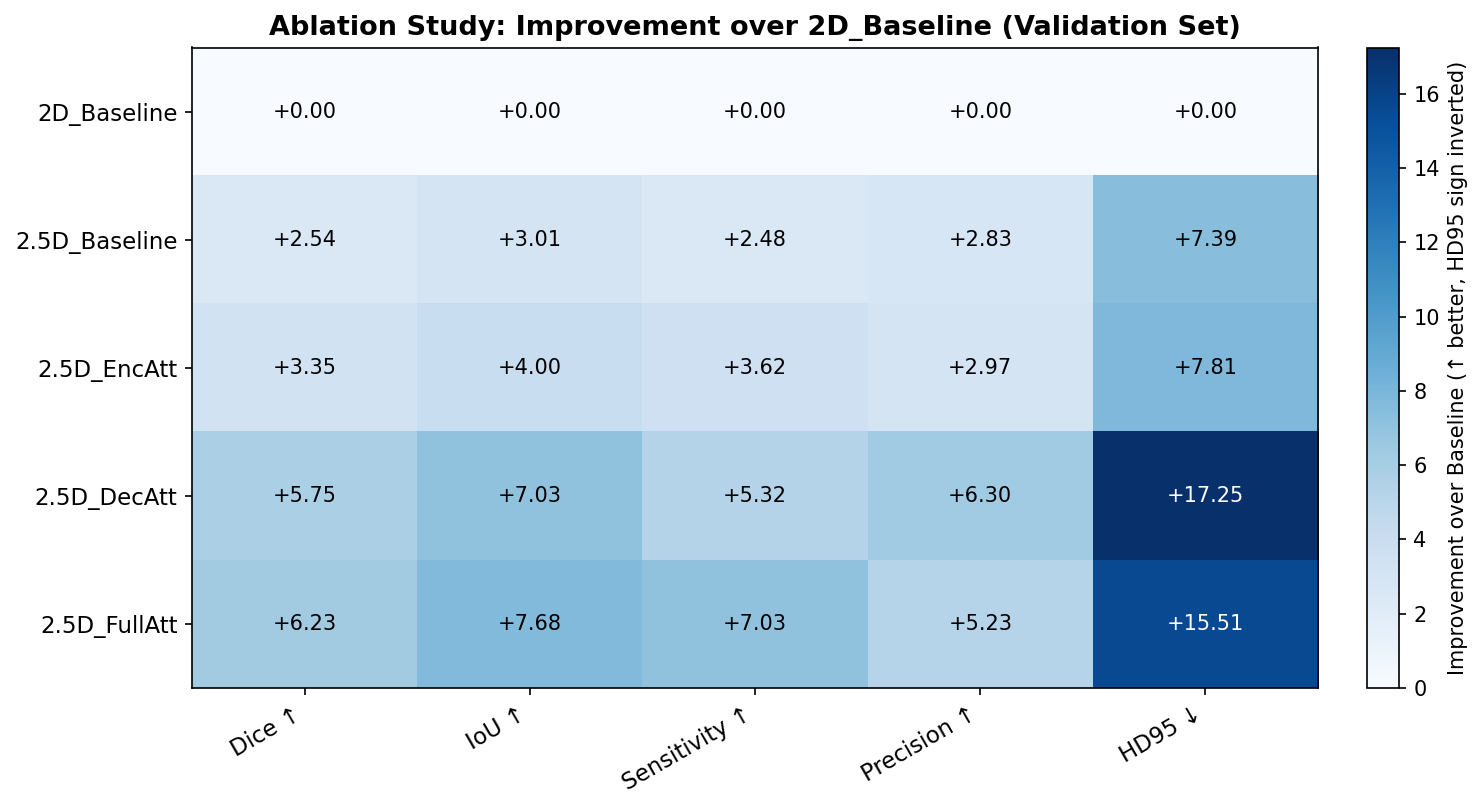

Figure saved successfully: Segmentation_Ablation_DeltaHeatmap.png


In [13]:

# ============================================================
# Figure 4: Improvement Heatmap over 2D_Baseline
# Segmentation Ablation Study — Validation Set
#
# Values are taken from the final CI summary table
# (mean across five seeds), as reported in Section 4.4.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

experiments = [
    "2D_Baseline",
    "2.5D_Baseline",
    "2.5D_EncAtt",
    "2.5D_DecAtt",
    "2.5D_FullAtt",
]

# Column order: Dice, IoU, Sensitivity, Precision, HD95
# Values represent the mean results across five seeds.

data = np.array([
    [69.13, 52.84, 64.67, 74.27, 36.59],  # 2D_Baseline
    [71.67, 55.85, 67.15, 77.10, 29.20],  # 2.5D_Baseline
    [72.48, 56.84, 68.29, 77.24, 28.78],  # 2.5D_EncAtt
    [74.88, 59.87, 69.99, 80.57, 19.34],  # 2.5D_DecAtt
    [75.36, 60.52, 71.70, 79.50, 21.08],  # 2.5D_FullAtt
])

metrics = [
    "Dice ↑",
    "IoU ↑",
    "Sensitivity ↑",
    "Precision ↑",
    "HD95 ↓"
]


# ============================================================
# Calculate improvement over the 2D baseline
# ============================================================

baseline = data[0]
delta = data - baseline

# Invert the HD95 difference so that positive values
# consistently indicate improvement.

delta[:, -1] = -delta[:, -1]

# Convert negative zero values to positive zero.

delta[np.isclose(delta, 0)] = 0.0


# ============================================================
# Generate heatmap
# ============================================================

plt.figure(figsize=(10, 5.5), dpi=150)

im = plt.imshow(
    delta,
    aspect="auto",
    cmap="Blues",
    vmin=0,
    vmax=delta[1:].max()
)

plt.xticks(
    range(len(metrics)),
    metrics,
    rotation=30,
    ha="right",
    fontsize=11
)

plt.yticks(
    range(len(experiments)),
    experiments,
    fontsize=11
)

plt.title(
    "Ablation Study: Improvement over 2D_Baseline (Validation Set)",
    fontsize=13,
    fontweight="bold"
)


# ============================================================
# Add cell annotations
# ============================================================

for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):

        val = delta[i, j]

        # Use white text for darker cells and black text
        # for lighter cells.

        color = (
            "white"
            if val > delta[1:].max() * 0.55
            else "black"
        )

        plt.text(
            j,
            i,
            f"{val:+.2f}",
            ha="center",
            va="center",
            fontsize=10,
            color=color
        )


# ============================================================
# Colorbar and figure layout
# ============================================================

cbar = plt.colorbar(
    im,
    fraction=0.035,
    pad=0.04
)

cbar.set_label(
    "Improvement over Baseline (↑ better, HD95 sign inverted)",
    fontsize=10
)

plt.tight_layout()


# ============================================================
# Save and display figure
# ============================================================

output_file = "Segmentation_Ablation_DeltaHeatmap.png"

plt.savefig(
    output_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Figure saved successfully: {output_file}")


-----------------------------

### Figure 5 — Validation Precision–Recall Curves — Main Ablation Study

This cell evaluates the five segmentation models on the validation set using the saved checkpoints from a single independent run (Seed 41).

For each model, the corresponding checkpoint is loaded, and pixel-level predictions are collected on the validation set. Precision–Recall curves and Average Precision (AP) are then calculated to compare the segmentation performance of the five architectures.

The cell displays the Precision–Recall curves and an AP summary table for the five models..

Device: cuda

Checking checkpoint availability...
[OK] 2D_Baseline
[OK] 2.5D_Baseline
[OK] 2.5D_EncAtt
[OK] 2.5D_DecAtt
[OK] 2.5D_FullAtt


Loading: 2D_Baseline
Validation samples: 2,082
Checkpoint loaded successfully.
2D_Baseline: AP = 0.6782

Loading: 2.5D_Baseline
Validation samples: 2,082
Checkpoint loaded successfully.
2.5D_Baseline: AP = 0.7172

Loading: 2.5D_EncAtt
Validation samples: 2,082
Checkpoint loaded successfully.
2.5D_EncAtt: AP = 0.7343

Loading: 2.5D_DecAtt
Validation samples: 2,082
Checkpoint loaded successfully.
2.5D_DecAtt: AP = 0.7548

Loading: 2.5D_FullAtt
Validation samples: 2,082
Checkpoint loaded successfully.
2.5D_FullAtt: AP = 0.7248

Validation Average Precision


,Model,AP
0,2D_Baseline,0.678248
1,2.5D_Baseline,0.717246
2,2.5D_EncAtt,0.734255
3,2.5D_DecAtt,0.754822
4,2.5D_FullAtt,0.724784


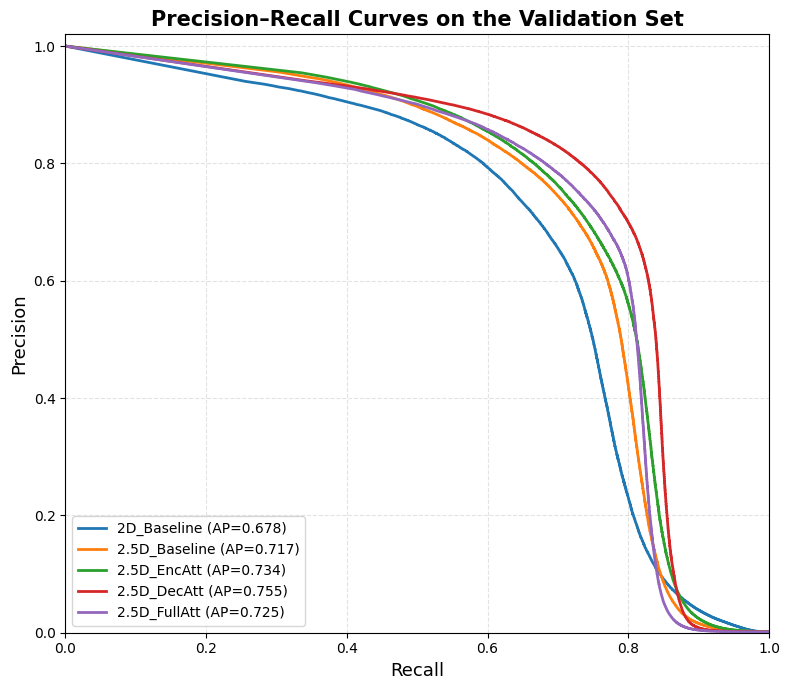


AP results saved successfully: Validation_PR_AP_Comparison_S41.csv

Validation PR analysis completed successfully.


In [ ]:

# ============================================================
# CELL: Validation Precision–Recall Curves
# Main Ablation Study — Five Segmentation Models
# Representative Run: Seed 41
# ============================================================

import os
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)


# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"Device: {device}")


# ============================================================
# 2. CHECKPOINT CONFIGURATION
# ============================================================

CHECKPOINT_DIR = "Checkpoints"

CHECKPOINTS = {
    "2D_Baseline": os.path.join(
        CHECKPOINT_DIR,
        f"best_model_Baseline_2D_S{SEED}.pt"
    ),

    "2.5D_Baseline": os.path.join(
        CHECKPOINT_DIR,
        f"best_model_Baseline_2.5D_S{SEED}.pt"
    ),

    "2.5D_EncAtt": os.path.join(
        CHECKPOINT_DIR,
        f"best_model_2.5D_EncAtt_S{SEED}.pt"
    ),

    "2.5D_DecAtt": os.path.join(
        CHECKPOINT_DIR,
        f"best_model_2.5D_DecAtt_S{SEED}.pt"
    ),

    "2.5D_FullAtt": os.path.join(
        CHECKPOINT_DIR,
        f"best_model_2.5D_FullAtt_S{SEED}.pt"
    ),
}


# ============================================================
# 3. CHECK CHECKPOINT AVAILABILITY
# ============================================================

print("\nChecking checkpoint availability...")

for name, path in CHECKPOINTS.items():

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Checkpoint not found for {name}."
        )

    print(f"[OK] {name}")


# ============================================================
# 4. MODEL CONFIGURATION
# ============================================================

MODEL_CONFIGS = {

    "2D_Baseline": {
        "in_ch": 1,
        "use_enc_att": False,
        "use_dec_att": False,
        "use_low_att": False,
    },

    "2.5D_Baseline": {
        "in_ch": 3,
        "use_enc_att": False,
        "use_dec_att": False,
        "use_low_att": False,
    },

    "2.5D_EncAtt": {
        "in_ch": 3,
        "use_enc_att": True,
        "use_dec_att": False,
        "use_low_att": False,
    },

    "2.5D_DecAtt": {
        "in_ch": 3,
        "use_enc_att": False,
        "use_dec_att": True,
        "use_low_att": False,
    },

    "2.5D_FullAtt": {
        "in_ch": 3,
        "use_enc_att": True,
        "use_dec_att": True,
        "use_low_att": True,
        "use_low_att": False,

    },
}


# ============================================================
# 5. VALIDATION DATASET AND LOADER
# ============================================================

# The same validation IDs and dataset configuration
# used in the main ablation study are retained.

BATCH_SIZE = 16

NUM_WORKERS = globals().get("NUM_WORKERS", 0)


def make_validation_loader(model_name):

    cfg = MODEL_CONFIGS[model_name]

    val_dataset = AblationDataset(
        val_ids,
        train=False,
        use_25d=(cfg["in_ch"] == 3),
        use_crop=False
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )

    return val_loader


# ============================================================
# 6. LOAD MODEL AND CHECKPOINT
# ============================================================

def load_checkpoint_model(model_name):

    cfg = MODEL_CONFIGS[model_name]

    model = SwinUNetAdaptive_DS(
        in_ch=cfg["in_ch"],
        base="timm",
        out_ch=1,
        use_enc_att=cfg["use_enc_att"],
        use_dec_att=cfg["use_dec_att"],
        use_low_att=cfg["use_low_att"],
        att_combine_method="max",
        patch_size=PATCH_SIZE
    ).to(device)

    checkpoint_path = CHECKPOINTS[model_name]

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    # Support different checkpoint dictionary formats.

    if isinstance(checkpoint, dict):

        if "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]

        elif "model_state" in checkpoint:
            state_dict = checkpoint["model_state"]

        elif "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]

        else:
            state_dict = checkpoint

    else:
        state_dict = checkpoint

    # Load model weights.

    missing, unexpected = model.load_state_dict(
        state_dict,
        strict=False
    )

    if len(missing) > 0:
        print(
            f"[WARNING] {model_name}: "
            f"{len(missing)} missing keys."
        )

    if len(unexpected) > 0:
        print(
            f"[WARNING] {model_name}: "
            f"{len(unexpected)} unexpected keys."
        )

    model.eval()

    return model


# ============================================================
# 7. COLLECT VALIDATION PREDICTIONS
# ============================================================

@torch.no_grad()
def collect_probs(model, loader):

    model.eval()

    y_true_all = []
    y_prob_all = []

    for batch in loader:

        # Support dictionary-style and tuple-style datasets.

        if isinstance(batch, dict):

            x = batch["image"]
            y = batch["mask"]

        else:
            x, y = batch

        x = x.to(
            device,
            non_blocking=True
        )

        y = y.to(
            device,
            non_blocking=True
        )

        # Forward pass.

        out = model(x)

        if isinstance(out, (tuple, list)):
            out = out[0]

        prob = torch.sigmoid(out)

        y_true_all.append(
            y.detach().float().cpu()
        )

        y_prob_all.append(
            prob.detach().float().cpu()
        )

    y_true = torch.cat(
        y_true_all,
        dim=0
    )

    y_prob = torch.cat(
        y_prob_all,
        dim=0
    )

    return y_true, y_prob


# ============================================================
# 8. FLATTEN PREDICTIONS
# ============================================================

def flatten_for_metrics(y_true, y_prob):

    y_true_f = (
        y_true
        .reshape(-1)
        .numpy()
    )

    y_prob_f = (
        y_prob
        .reshape(-1)
        .numpy()
    )

    return y_true_f, y_prob_f


# ============================================================
# 9. COLLECT PREDICTIONS FOR ALL FIVE MODELS
# ============================================================

results_val = {}

print("\n" + "=" * 70)
print("Collecting validation predictions")
print("=" * 70)

for model_name in MODEL_CONFIGS.keys():

    print(f"\nLoading: {model_name}")

    # Create validation loader.

    val_loader = make_validation_loader(
        model_name
    )

    print(
        f"Validation samples: "
        f"{len(val_loader.dataset):,}"
    )

    # Load saved checkpoint.

    model = load_checkpoint_model(
        model_name
    )

    print("Checkpoint loaded successfully.")

    # Collect validation predictions.

    y_true, y_prob = collect_probs(
        model,
        val_loader
    )

    y_true_f, y_prob_f = flatten_for_metrics(
        y_true,
        y_prob
    )

    # Calculate Average Precision.

    ap = average_precision_score(
        y_true_f,
        y_prob_f
    )

    results_val[model_name] = {
        "y_true": y_true_f,
        "y_prob": y_prob_f,
        "AP": ap
    }

    print(
        f"{model_name}: "
        f"AP = {ap:.4f}"
    )

    # Release resources.

    del model
    del val_loader

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    gc.collect()


# ============================================================
# 10. AVERAGE PRECISION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("Validation Average Precision")
print("=" * 70)

ap_rows = []

for name, res in results_val.items():

    ap_rows.append({
        "Model": name,
        "AP": res["AP"]
    })

ap_df = pd.DataFrame(ap_rows)

display(ap_df)


# ============================================================
# 11. PRECISION–RECALL CURVES
# ============================================================

plt.figure(
    figsize=(8, 7)
)

for name, res in results_val.items():

    y_true_f = res["y_true"]
    y_prob_f = res["y_prob"]

    precision, recall, _ = precision_recall_curve(
        y_true_f,
        y_prob_f
    )

    ap = res["AP"]

    plt.plot(
        recall,
        precision,
        lw=2,
        label=f"{name} (AP={ap:.3f})"
    )


# Configure plot appearance.

plt.xlabel(
    "Recall",
    fontsize=13
)

plt.ylabel(
    "Precision",
    fontsize=13
)

plt.title(
    "Precision–Recall Curves on the Validation Set",
    fontsize=15,
    fontweight="bold"
)

plt.xlim(
    0,
    1
)

plt.ylim(
    0,
    1.02
)

plt.grid(
    True,
    linestyle="--",
    alpha=0.35
)

plt.legend(
    loc="lower left",
    fontsize=10
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. SAVE AVERAGE PRECISION RESULTS
# ============================================================

ap_csv_path = (
    f"Validation_PR_AP_Comparison_S{SEED}.csv"
)

ap_df.to_csv(
    ap_csv_path,
    index=False
)

print(
    f"\nAP results saved successfully: "
    f"{ap_csv_path}"
)

print("\nValidation PR analysis completed successfully.")


----------------------

### Qualitative Segmentation Results

This cell presents qualitative segmentation results for the proposed 2.5D_DecAtt model on the test set. It selects the best, middle, and worst cases based on Dice scores for both large and small nodules. For each case, it displays the original CT image, ground-truth mask, predicted mask, and error map. True-positive, false-positive, and false-negative regions are shown in green, blue, and red, respectively. The ground-truth area, predicted area, and absolute pixel difference are also reported. These visual results are presented in **Figure 9** and complement the quantitative error analysis in Table 11.

Training samples: 9,845
Validation samples: 2,082
Test samples: 2,016
Test loader created.
Test samples: 2016
Model loaded successfully: 2.5D_DecAtt
Device: cuda

Evaluating test samples...
Processed batches: 10
Processed batches: 20
Processed batches: 30
Processed batches: 40
Processed batches: 50
Processed batches: 60
Processed batches: 70
Processed batches: 80
Processed batches: 90
Processed batches: 100
Processed batches: 110
Processed batches: 120

Eligible test samples: 2016


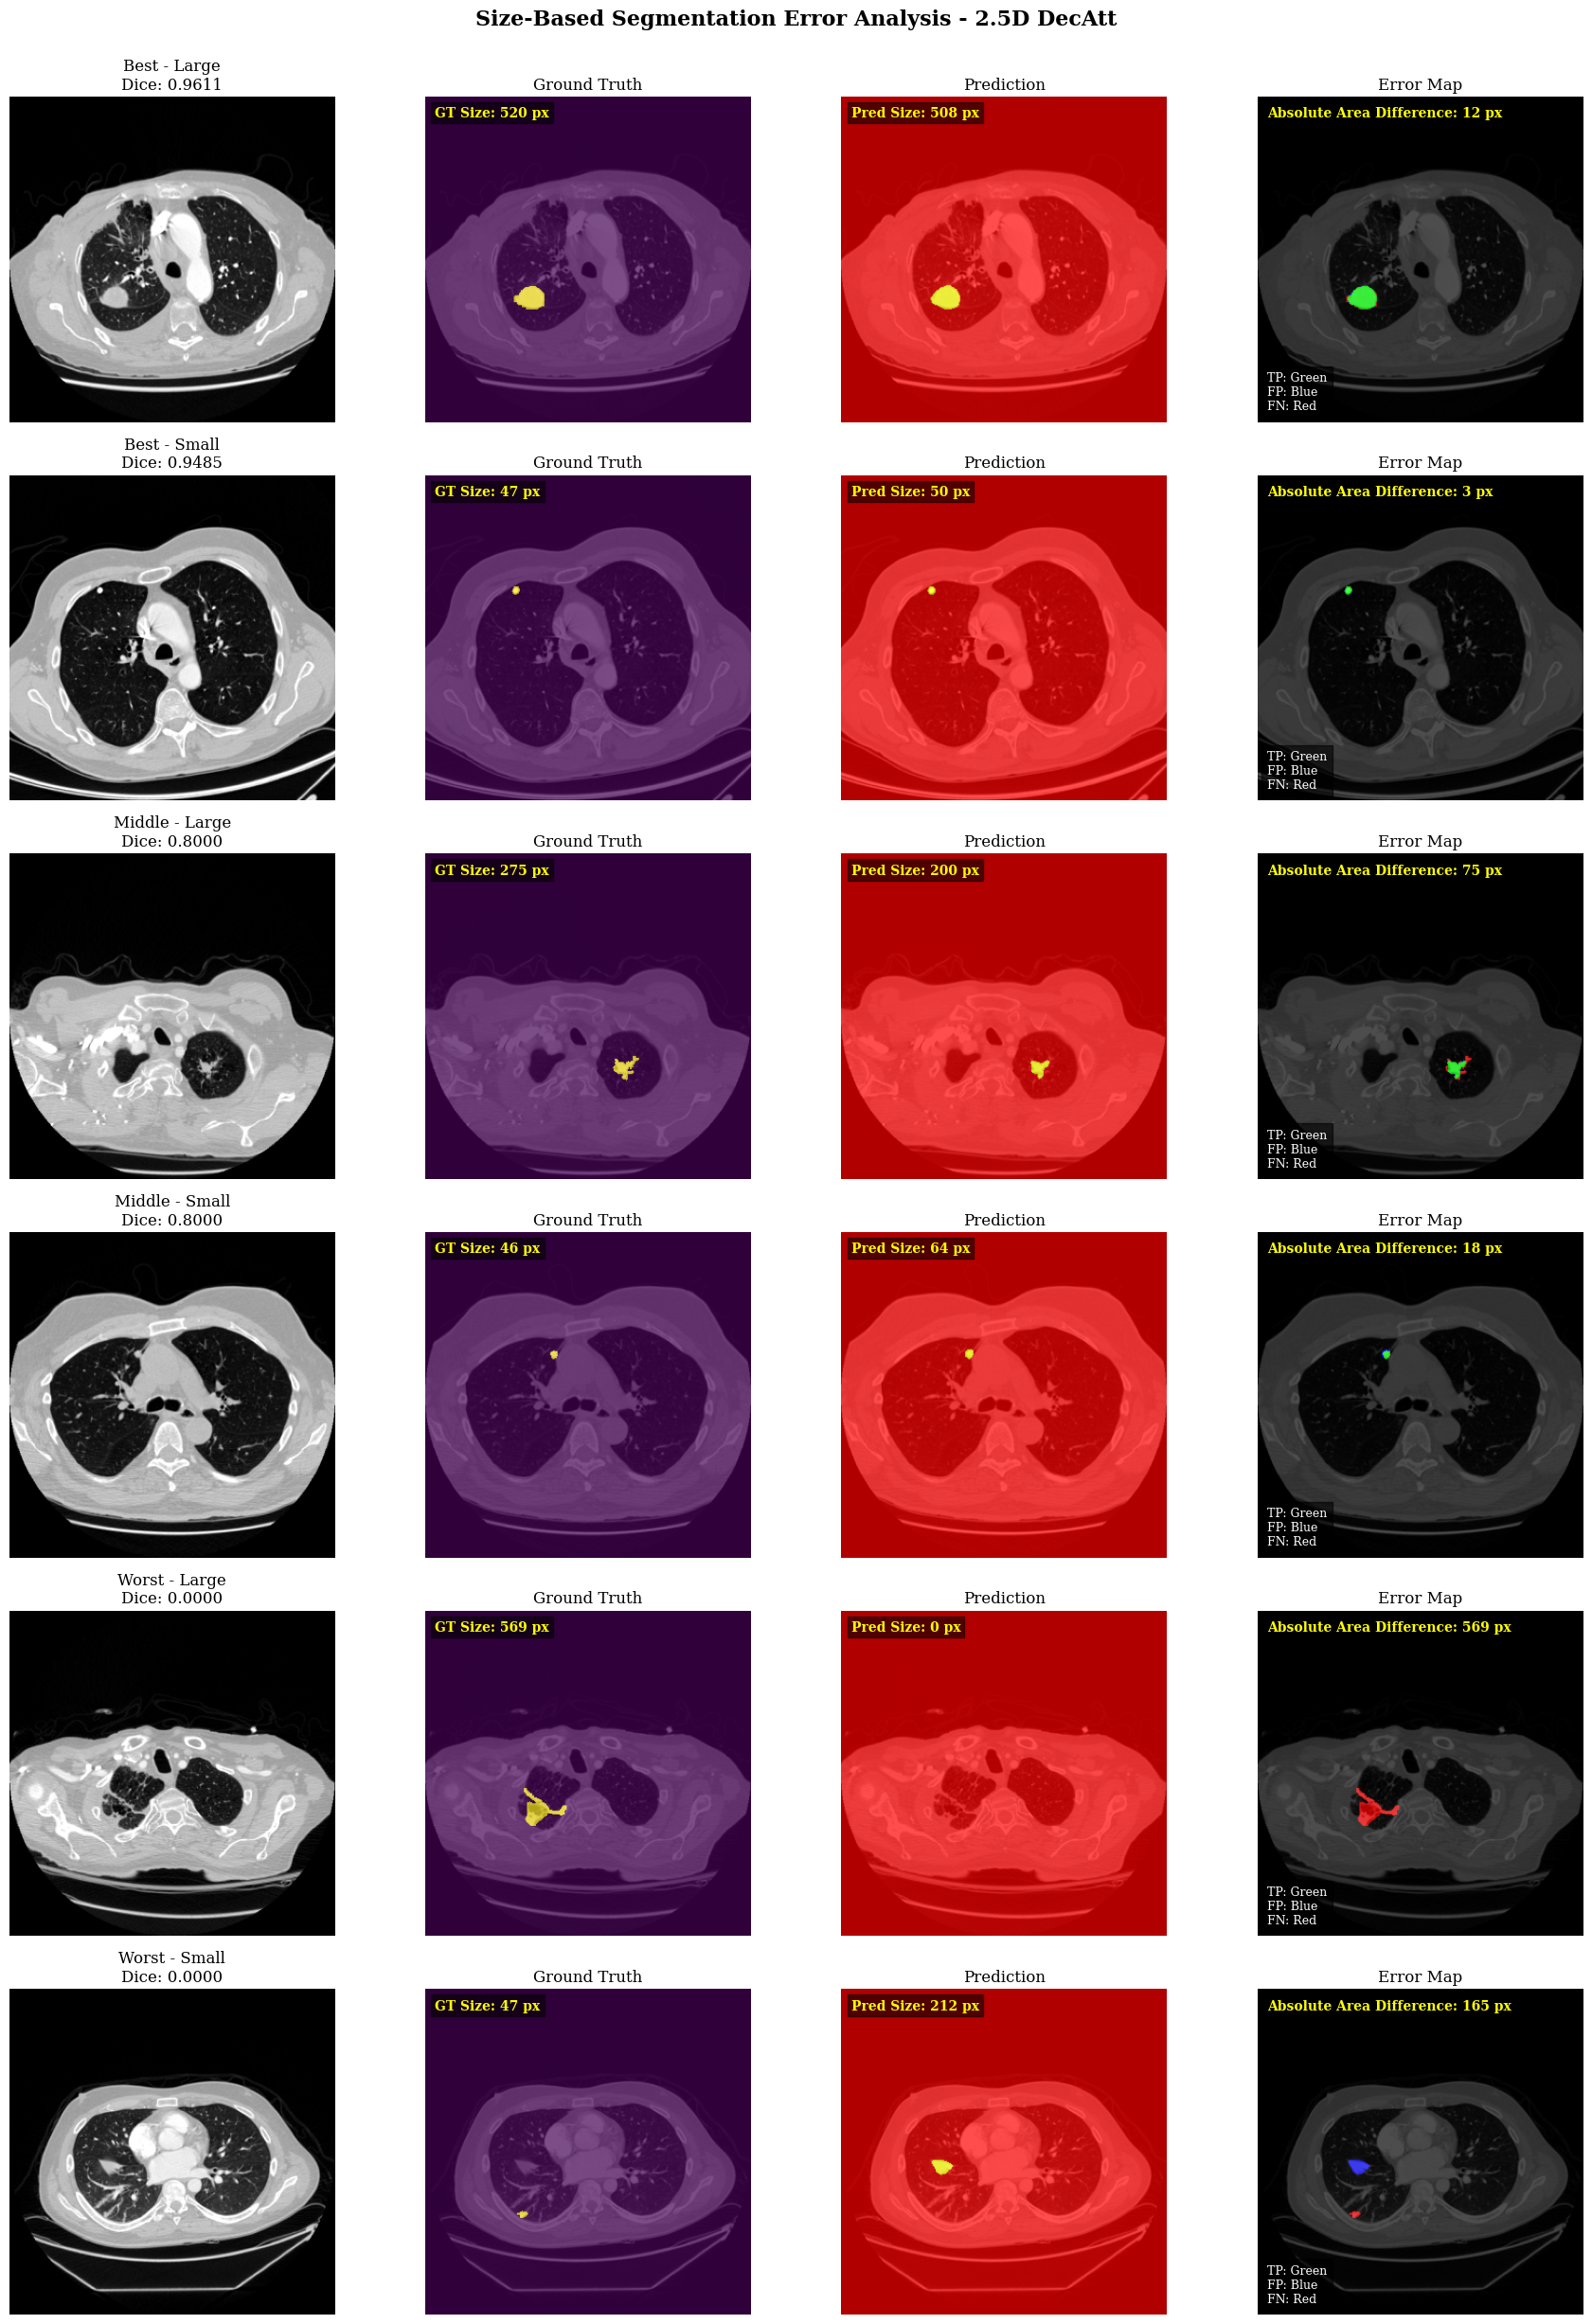


========== SELECTED TEST CASES ==========
Best - Large    | Dice: 0.9611 | GT: 520 px | Pred: 508 px | Area difference: 12 px
Best - Small    | Dice: 0.9485 | GT: 47 px | Pred: 50 px | Area difference: 3 px
Middle - Large  | Dice: 0.8000 | GT: 275 px | Pred: 200 px | Area difference: 75 px
Middle - Small  | Dice: 0.8000 | GT: 46 px | Pred: 64 px | Area difference: 18 px
Worst - Large   | Dice: 0.0000 | GT: 569 px | Pred: 0 px | Area difference: 569 px
Worst - Small   | Dice: 0.0000 | GT: 47 px | Pred: 212 px | Area difference: 165 px


In [ ]:

# ============================================================
# SIZE-BASED SEGMENTATION ERROR ANALYSIS
# 2.5D_DecAtt | Full-Size 320x320 | Test Set
#
# 1. Loads the selected segmentation checkpoint.
# 2. Evaluates all test samples with non-empty GT masks.
# 3. Selects best, middle, and worst Dice cases.
# 4. Selects the largest and smallest nodules in each group.
# 5. Visualizes CT, GT, prediction, and error maps.
#
# Error map:
#   TP = Green | FP = Blue | FN = Red
# ============================================================

import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURATION
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODEL_NAME = "2.5D_DecAtt"
IN_CHANNELS = 3
IMG_SIZE = 320
BATCH_SIZE = 16
USE_CROP = False

SEG_CKPT_PATH = r"best_model_2.5D_DecAtt.pt"

N_PER_GROUP = 20

# ============================================================
# 2. CHECK REQUIRED DEFINITIONS
# ============================================================

required = [
    "SwinUNetAdaptive_DS",
    "make_loaders_ablation",
    "train_ids",
    "val_ids",
    "test_ids",
    "pairs",
    "BATCH_SIZE",
    "NUM_WORKERS",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise NameError(
        f"Missing required definitions: {missing}. "
        "Run the model, split, and DataLoader setup cells first."
    )

if not os.path.exists(SEG_CKPT_PATH):
    raise FileNotFoundError(SEG_CKPT_PATH)

# ============================================================
# 3. CREATE TEST LOADER
# ============================================================

_, _, test_loader = make_loaders_ablation(
    train_ids=train_ids,
    val_ids=val_ids,
    test_ids=test_ids,
    use_25d=True,
    use_crop=False,
    batch_size=BATCH_SIZE,
    fraction=1.0,
    max_slices_per_patient=None,
    num_workers=NUM_WORKERS,
)

print("Test loader created.")
print("Test samples:", len(test_loader.dataset))

# ============================================================
# 4. LOAD SEGMENTATION MODEL
# ============================================================

model = SwinUNetAdaptive_DS(
    in_ch=IN_CHANNELS,
    use_enc_att=False,
    use_dec_att=True
).to(device)

checkpoint = torch.load(
    SEG_CKPT_PATH,
    map_location=device
)

if isinstance(checkpoint, dict):
    state_dict = None

    for key in ["model_state_dict", "state_dict", "model_state"]:
        if key in checkpoint:
            state_dict = checkpoint[key]
            break

    if state_dict is None:
        state_dict = checkpoint
else:
    state_dict = checkpoint

model.load_state_dict(state_dict)
model.eval()

for param in model.parameters():
    param.requires_grad_(False)

print("Model loaded successfully:", MODEL_NAME)
print("Device:", device)

# ============================================================
# 5. DICE CALCULATION
# ============================================================

def calculate_dice(pred, target):

    smooth = 1e-5

    pred = (pred > 0.5).float()
    target = (target > 0.5).float()

    intersection = (pred * target).sum()

    return (
        (2.0 * intersection + smooth) /
        (pred.sum() + target.sum() + smooth)
    )


# ============================================================
# 6. EVALUATE TEST SAMPLES
# ============================================================

def collect_test_results(model, test_loader, device):

    model.eval()
    all_results = []

    print("\nEvaluating test samples...")

    with torch.no_grad():

        for batch_idx, (images, masks) in enumerate(test_loader):

            images = images.to(device)
            masks = masks.to(device)

            outputs = model(images)

            if isinstance(outputs, (tuple, list)):
                outputs = outputs[0]

            preds = (torch.sigmoid(outputs) > 0.5).float()

            for i in range(images.size(0)):

                gt = masks[i, 0]
                pred = preds[i, 0]

                dice = calculate_dice(pred, gt).item()

                gt_size = int((gt > 0.5).sum().item())

                if gt_size == 0:
                    continue

                pred_size = int((pred > 0.5).sum().item())

                # Central axial slice of the 2.5D input
                img = images[i, 1].detach().cpu()

                all_results.append({
                    "dice": dice,
                    "size": gt_size,
                    "pred_size": pred_size,
                    "image": img,
                    "mask": gt.detach().cpu(),
                    "pred": pred.detach().cpu()
                })

            if (batch_idx + 1) % 10 == 0:
                print(f"Processed batches: {batch_idx + 1}")

    if len(all_results) < 3:
        raise ValueError("Not enough eligible test samples.")

    print("\nEligible test samples:", len(all_results))

    return all_results


# ============================================================
# 7. SELECT REPRESENTATIVE CASES
# ============================================================

def select_representative_cases(all_results):

    sorted_results = sorted(
        all_results,
        key=lambda x: x["dice"]
    )

    pool_size = min(
        N_PER_GROUP,
        max(1, len(sorted_results) // 3)
    )

    worst_pool = sorted_results[:pool_size]
    best_pool = sorted_results[-pool_size:]

    mid_idx = len(sorted_results) // 2
    half_pool = pool_size // 2

    start = max(0, mid_idx - half_pool)
    end = min(len(sorted_results), start + pool_size)

    average_pool = sorted_results[start:end]

    def get_large_and_small(pool):

        ordered = sorted(
            pool,
            key=lambda x: x["size"]
        )

        return ordered[-1], ordered[0]

    selected = (
        list(get_large_and_small(best_pool)) +
        list(get_large_and_small(average_pool)) +
        list(get_large_and_small(worst_pool))
    )

    labels = [
        "Best - Large",
        "Best - Small",
        "Middle - Large",
        "Middle - Small",
        "Worst - Large",
        "Worst - Small"
    ]

    return selected, labels


# ============================================================
# 8. VISUALIZE SELECTED CASES
# ============================================================

def visualize_size_based_cases(selected_cases, row_labels):

    fig, axes = plt.subplots(
        6, 4,
        figsize=(18, 25)
    )

    fig.suptitle(
        "Size-Based Segmentation Error Analysis - 2.5D DecAtt",
        fontsize=16,
        fontweight="bold"
    )

    text_kwargs = dict(
        color="yellow",
        fontsize=10,
        fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.55, pad=3),
        va="top",
        ha="left"
    )

    for row_idx, case in enumerate(selected_cases):

        img = case["image"].numpy()
        gt = case["mask"].numpy() > 0.5
        pred = case["pred"].numpy() > 0.5

        tp = pred & gt
        fp = pred & ~gt
        fn = ~pred & gt

        error_map = np.zeros(
            (*gt.shape, 3),
            dtype=np.float32
        )

        error_map[tp] = [0, 1, 0]
        error_map[fp] = [0, 0, 1]
        error_map[fn] = [1, 0, 0]

        gt_size = case["size"]
        pred_size = case["pred_size"]
        abs_diff = abs(gt_size - pred_size)

        # CT
        axes[row_idx, 0].imshow(img, cmap="gray")
        axes[row_idx, 0].set_title(
            f"{row_labels[row_idx]}\nDice: {case['dice']:.4f}"
        )
        axes[row_idx, 0].axis("off")

        # Ground Truth
        axes[row_idx, 1].imshow(img, cmap="gray")
        axes[row_idx, 1].imshow(
            gt, cmap="viridis", alpha=0.7
        )
        axes[row_idx, 1].set_title("Ground Truth")
        axes[row_idx, 1].text(
            0.03, 0.97,
            f"GT Size: {gt_size} px",
            transform=axes[row_idx, 1].transAxes,
            **text_kwargs
        )
        axes[row_idx, 1].axis("off")

        # Prediction
        axes[row_idx, 2].imshow(img, cmap="gray")
        axes[row_idx, 2].imshow(
            pred, cmap="autumn", alpha=0.7
        )
        axes[row_idx, 2].set_title("Prediction")
        axes[row_idx, 2].text(
            0.03, 0.97,
            f"Pred Size: {pred_size} px",
            transform=axes[row_idx, 2].transAxes,
            **text_kwargs
        )
        axes[row_idx, 2].axis("off")

        # Error Map
        axes[row_idx, 3].imshow(img, cmap="gray")
        axes[row_idx, 3].imshow(error_map, alpha=0.7)
        axes[row_idx, 3].set_title("Error Map")
        axes[row_idx, 3].text(
            0.03, 0.97,
            f"Absolute Area Difference: {abs_diff} px",
            transform=axes[row_idx, 3].transAxes,
            **text_kwargs
        )
        axes[row_idx, 3].text(
            0.03, 0.03,
            "TP: Green\nFP: Blue\nFN: Red",
            color="white",
            fontsize=9,
            transform=axes[row_idx, 3].transAxes,
            bbox=dict(facecolor="black", alpha=0.6),
            va="bottom",
            ha="left"
        )
        axes[row_idx, 3].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()


# ============================================================
# 9. RUN ANALYSIS
# ============================================================

all_results = collect_test_results(
    model,
    test_loader,
    device
)

selected_cases, row_labels = select_representative_cases(
    all_results
)

visualize_size_based_cases(
    selected_cases,
    row_labels
)

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n========== SELECTED TEST CASES ==========")

for label, case in zip(row_labels, selected_cases):

    print(
        f"{label:15s} | "
        f"Dice: {case['dice']:.4f} | "
        f"GT: {case['size']} px | "
        f"Pred: {case['pred_size']} px | "
        f"Area difference: "
        f"{abs(case['size'] - case['pred_size'])} px"
    )
